# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
from encodings import koi8_r
from locale import locale_alias

from os.path import join
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = join("..","Data", "clients.csv")
RAW_TXN = join("..","Data", "transactions.csv")


## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

### 1.1 Загрузка Clients

In [2]:
with open(RAW_CLIENTS, encoding='utf-8') as f:
    for _ in range(3):
        print(repr(f.readline()))


'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
'C002335,1972-07-31,М,г. Москва,Премиальный,Платина,Премиальная,16.03.2017,14.10.2017,Зарплата в нашем банке,124100.0,Да,2024-12,5,00937,Да\n'
'C002412,1958-06-13,М,Москва,Массовый,Базовый,Дебетовая,11.01.2016,21.05.2016,Не указан,,Нет,,2,00523,Да\n'


In [3]:
DATA_COLS=["birth_date","app_last_login", "registration_date","card_open_date"]

CATEGORIAL_COLS=["gender", "segment", "loyalty_tier","loyalty_tier", "card_type",
                 "income_source", "has_mobile_app","satisfaction_score", "marketing_opt_in"]

dfClientsRaw=pd.read_csv(
    RAW_CLIENTS,
    parse_dates=DATA_COLS,
    dayfirst=True,
    date_format={"birth_date":"%Y-%m-%d", "app_last_login":"%Y-%m"})




dfClientsRaw.info()
dfClientsRaw.head()

<class 'pandas.DataFrame'>
RangeIndex: 5715 entries, 0 to 5714
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5715 non-null   str           
 1   birth_date          5715 non-null   datetime64[us]
 2   gender              5715 non-null   str           
 3   city                5715 non-null   str           
 4   segment             5715 non-null   str           
 5   loyalty_tier        5715 non-null   str           
 6   card_type           5715 non-null   str           
 7   registration_date   5715 non-null   datetime64[us]
 8   card_open_date      5715 non-null   datetime64[us]
 9   income_source       5715 non-null   str           
 10  monthly_income      5205 non-null   float64       
 11  has_mobile_app      5715 non-null   str           
 12  app_last_login      3553 non-null   datetime64[us]
 13  satisfaction_score  2336 non-null   float64       
 14  bra

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C002335,1972-07-31,М,г. Москва,Премиальный,Платина,Премиальная,2017-03-16,2017-10-14,Зарплата в нашем банке,124100.0,Да,2024-12-01,5.0,937,Да
1,C002412,1958-06-13,М,Москва,Массовый,Базовый,Дебетовая,2016-01-11,2016-05-21,Не указан,NaN,Нет,NaT,2.0,523,Да
2,C001206,1973-04-11,М,Нижний Новгород,Массовый,Базовый,Дебетовая,2017-01-08,2022-04-05,Зарплата в другом банке,81700.0,Да,2024-07-01,NaN,556,Нет
3,C000993,1971-07-08,М,г. Москва,Массовый,Базовый,Дебетовая,2019-02-17,2022-10-06,Зарплата в нашем банке,52100.0,Да,2024-08-01,2.0,164,Нет
4,C005096,1964-07-04,М,Екатеринбург,Массовый,Базовый,Дебетовая,2014-06-27,2018-05-06,Зарплата в другом банке,85500.0,Нет,NaT,2.0,117,Да


### 1.1 Загрузка Transactions

In [4]:
with open(RAW_TXN, encoding='cp1251') as f:
    for _ in range(3):
        print(repr(f.readline()))


'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990080;C000334;2023-12-04 16:03:32;2453,06;RUB;Кафе и рестораны;5812;СБП;успешно\n'
'990128;C004909;2023-12-09 15:20:06;4141,73;RUB;Кафе и рестораны;5812;Карта;успешно\n'


In [5]:
dfTransactionsRaw = pd.read_csv(
    RAW_TXN,
    sep=";",
    decimal=",",
    encoding="cp1251",
)
dfTransactionsRaw.info()
dfTransactionsRaw.head()

<class 'pandas.DataFrame'>
RangeIndex: 628989 entries, 0 to 628988
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   txn_id        628989 non-null  int64  
 1   client_id     628989 non-null  str    
 2   txn_datetime  628989 non-null  str    
 3   amount        628989 non-null  float64
 4   currency      628989 non-null  str    
 5   category      628989 non-null  str    
 6   mcc_code      628989 non-null  int64  
 7   channel       628989 non-null  str    
 8   status        628989 non-null  str    
dtypes: float64(1), int64(2), str(6)
memory usage: 87.9 MB


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990080,C000334,2023-12-04 16:03:32,2453.06,RUB,Кафе и рестораны,5812,СБП,успешно
1,990128,C004909,2023-12-09 15:20:06,4141.73,RUB,Кафе и рестораны,5812,Карта,успешно
2,990174,C002718,2023-12-11 16:01:17,1316.19,RUB,Продукты,5411,Онлайн-банк,успешно
3,100001,C000655,2024-01-01 01:11:42,750.36,RUB,Онлайн-сервисы,5815,Карта,успешно
4,100002,C003170,2024-01-01 01:14:47,957.10,RUB,Продукты,5411,Онлайн-банк,успешно


In [6]:
# print(dfClientsRaw["loyalty_tier"].unique(), "\n")
# print(dfClientsRaw["satisfaction_score"].unique(), "\n")
#
# CATEGORIAL_COLS=["gender", "segment", "loyalty_tier", "card_type",
#                  "income_source", "has_mobile_app","satisfaction_score","marketing_opt_in"]
#
# LOYALTY_TIER_GRADE=[ "Базовый", "Серебро", "Золото","Платина"]
#
# SATISFACTION_SCORE_GRADE=[1.,2.,3.,4.,5]
#
# dfClientsRaw=dfClientsRaw.assign(
#     gender=dfClientsRaw["gender"].astype('category'),
#     segment=dfClientsRaw["segment"].astype('category'),
#     loyalty_tier=pd.Categorical(dfClientsRaw["loyalty_tier"],categories=LOYALTY_TIER_GRADE, ordered=True ),
#     card_type=dfClientsRaw["card_type"].astype('category'),
#     income_source=dfClientsRaw["income_source"].astype('category'),
#     has_mobile_app=dfClientsRaw["has_mobile_app"].map({"Да":True, "Нет":False}),
#     satisfaction_score=pd.Categorical(dfClientsRaw["satisfaction_score"] ,ordered=True ),
#     marketing_opt_in=dfClientsRaw["marketing_opt_in"].map({"Да":True, "Нет":False})
# )
#
#
# dfClientsRaw.info()
# dfClientsRaw.head()

## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

#### 2.1.1 Объём, типы, ключи, единица наблюдения для Clients

In [7]:
overviewClientsRaw = pd.DataFrame({
    'dtype': dfClientsRaw.dtypes.astype(str),
    'n_unique': dfClientsRaw.nunique(),
    'n_missing': dfClientsRaw.isna().sum(),
    'missing_%': (dfClientsRaw.isna().mean() * 100).round(2),
    'example': dfClientsRaw.iloc[100],
})
overviewClientsRaw

,dtype,n_unique,n_missing,missing_%,example
client_id,str,5660,0,0.00,C005092
birth_date,datetime64[us],4822,0,0.00,1955-12-09 00:00:00
gender,str,2,0,0.00,Ж
city,str,17,0,0.00,Казань
segment,str,4,0,0.00,Массовый
loyalty_tier,str,4,0,0.00,Базовый
card_type,str,3,0,0.00,Дебетовая
registration_date,datetime64[us],3212,0,0.00,2017-07-20 00:00:00
card_open_date,datetime64[us],2652,0,0.00,2020-01-30 00:00:00
income_source,str,3,0,0.00,Зарплата в нашем банке


#### 2.1.2 Объём, типы, ключи, единица наблюдения для Transactions


In [8]:
overviewTransactionsRaw = pd.DataFrame({
    'dtype': dfTransactionsRaw.dtypes.astype(str),
    'n_unique': dfTransactionsRaw.nunique(),
    'n_missing': dfTransactionsRaw.isna().sum(),
    'missing_%': (dfTransactionsRaw.isna().mean() * 100).round(2),
    'example': dfTransactionsRaw.iloc[100],
})
overviewTransactionsRaw

,dtype,n_unique,n_missing,missing_%,example
txn_id,int64,627489,0,0.0,100098
client_id,str,5993,0,0.0,C004380
txn_datetime,str,571433,0,0.0,2024-01-01 10:08:09
amount,float64,327045,0,0.0,1918.81
currency,str,3,0,0.0,RUB
category,str,12,0,0.0,Кафе и рестораны
mcc_code,int64,9,0,0.0,5812
channel,str,4,0,0.0,Карта
status,str,3,0,0.0,успешно


### 2.2. Дубли

#### 2.2.1 Дубли для Clients

In [9]:
duplicatesClientsRaw=dfClientsRaw.duplicated(keep=False)
print("Кол-во полных дубликатов: ", dfClientsRaw.duplicated().sum())
print(dfClientsRaw[duplicatesClientsRaw].isnull().sum())
dfClientsRaw[duplicatesClientsRaw].sort_values(list(dfClientsRaw.columns)).head(10)

Кол-во полных дубликатов:  40
client_id              0
birth_date             0
gender                 0
city                   0
segment                0
loyalty_tier           0
card_type              0
registration_date      0
card_open_date         0
income_source          0
monthly_income        10
has_mobile_app         0
app_last_login        22
satisfaction_score    52
branch_code            0
marketing_opt_in       0
dtype: int64


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
211,C000308,1982-05-10,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,2017-08-19,2018-02-09,Не указан,61300.0,Да,2025-04-01,NaN,670,Да
1803,C000308,1982-05-10,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,2017-08-19,2018-02-09,Не указан,61300.0,Да,2025-04-01,NaN,670,Да
3447,C000325,1983-08-26,М,Москва,Массовый,Базовый,Дебетовая,2013-05-06,2017-08-31,Зарплата в нашем банке,52400.0,Да,2024-06-01,NaN,341,Да
4672,C000325,1983-08-26,М,Москва,Массовый,Базовый,Дебетовая,2013-05-06,2017-08-31,Зарплата в нашем банке,52400.0,Да,2024-06-01,NaN,341,Да
4803,C000358,1972-11-15,Ж,Екатеринбург,Зарплатный,Золото,Кредитная,2012-04-20,2016-06-24,Зарплата в нашем банке,63.0,Да,2025-02-01,4.0,114,Да
5702,C000358,1972-11-15,Ж,Екатеринбург,Зарплатный,Золото,Кредитная,2012-04-20,2016-06-24,Зарплата в нашем банке,63.0,Да,2025-02-01,4.0,114,Да
201,C001182,1967-04-23,Ж,МОСКВА,Зарплатный,Серебро,Дебетовая,2014-09-28,2019-02-16,Зарплата в нашем банке,117600.0,Нет,NaT,NaN,249,Нет
2984,C001182,1967-04-23,Ж,МОСКВА,Зарплатный,Серебро,Дебетовая,2014-09-28,2019-02-16,Зарплата в нашем банке,117600.0,Нет,NaT,NaN,249,Нет
1713,C001393,1982-07-03,М,Казань,Массовый,Серебро,Дебетовая,2018-07-27,2020-01-09,Не указан,52300.0,Нет,NaT,NaN,807,Да
3164,C001393,1982-07-03,М,Казань,Массовый,Серебро,Дебетовая,2018-07-27,2020-01-09,Не указан,52300.0,Нет,NaT,NaN,807,Да


In [10]:
duplicatesClientsIdRaw=dfClientsRaw["client_id"].duplicated(keep=False)
print("Кол-во дублированных ID клиентов :",duplicatesClientsIdRaw.sum())
print(dfClientsRaw[duplicatesClientsRaw].isnull().sum())
dfClientsRaw[duplicatesClientsRaw].sort_values(list(dfClientsRaw.columns)).head(10)

Кол-во дублированных ID клиентов : 110
client_id              0
birth_date             0
gender                 0
city                   0
segment                0
loyalty_tier           0
card_type              0
registration_date      0
card_open_date         0
income_source          0
monthly_income        10
has_mobile_app         0
app_last_login        22
satisfaction_score    52
branch_code            0
marketing_opt_in       0
dtype: int64


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
211,C000308,1982-05-10,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,2017-08-19,2018-02-09,Не указан,61300.0,Да,2025-04-01,NaN,670,Да
1803,C000308,1982-05-10,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,2017-08-19,2018-02-09,Не указан,61300.0,Да,2025-04-01,NaN,670,Да
3447,C000325,1983-08-26,М,Москва,Массовый,Базовый,Дебетовая,2013-05-06,2017-08-31,Зарплата в нашем банке,52400.0,Да,2024-06-01,NaN,341,Да
4672,C000325,1983-08-26,М,Москва,Массовый,Базовый,Дебетовая,2013-05-06,2017-08-31,Зарплата в нашем банке,52400.0,Да,2024-06-01,NaN,341,Да
4803,C000358,1972-11-15,Ж,Екатеринбург,Зарплатный,Золото,Кредитная,2012-04-20,2016-06-24,Зарплата в нашем банке,63.0,Да,2025-02-01,4.0,114,Да
5702,C000358,1972-11-15,Ж,Екатеринбург,Зарплатный,Золото,Кредитная,2012-04-20,2016-06-24,Зарплата в нашем банке,63.0,Да,2025-02-01,4.0,114,Да
201,C001182,1967-04-23,Ж,МОСКВА,Зарплатный,Серебро,Дебетовая,2014-09-28,2019-02-16,Зарплата в нашем банке,117600.0,Нет,NaT,NaN,249,Нет
2984,C001182,1967-04-23,Ж,МОСКВА,Зарплатный,Серебро,Дебетовая,2014-09-28,2019-02-16,Зарплата в нашем банке,117600.0,Нет,NaT,NaN,249,Нет
1713,C001393,1982-07-03,М,Казань,Массовый,Серебро,Дебетовая,2018-07-27,2020-01-09,Не указан,52300.0,Нет,NaT,NaN,807,Да
3164,C001393,1982-07-03,М,Казань,Массовый,Серебро,Дебетовая,2018-07-27,2020-01-09,Не указан,52300.0,Нет,NaT,NaN,807,Да


Количество полных дублей равно 40, а дублированных ID 110, что говорит о некорректном заполнении данных клиентов.

#### 2.2.1 Дубли для Transactions

In [11]:
duplicatesTransactionsRaw=dfTransactionsRaw.duplicated(keep=False)
print("Кол-во полных дубликатов:",dfTransactionsRaw.duplicated().sum())
dfTransactionsRaw[duplicatesTransactionsRaw].sort_values(list(dfTransactionsRaw.columns)).head(10)

Кол-во полных дубликатов: 1278


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
397,100395,C004487,2024-01-01 15:05:32,614.35,RUB,Продукты,5411,Карта,успешно
398,100395,C004487,2024-01-01 15:05:32,614.35,RUB,Продукты,5411,Карта,успешно
950,100947,C000506,2024-01-02 12:40:32,830.62,RUB,Связь и Интернет,4814,Карта,успешно
951,100947,C000506,2024-01-02 12:40:32,830.62,RUB,Связь и Интернет,4814,Карта,успешно
1720,101716,C003005,2024-01-03 13:12:59,1338.27,RUB,Продукты,5411,Карта,успешно
1721,101716,C003005,2024-01-03 13:12:59,1338.27,RUB,Продукты,5411,Карта,успешно
1912,101906,C005617,2024-01-03 16:13:51,138.38,RUB,Продукты,5411,Карта,успешно
1913,101906,C005617,2024-01-03 16:13:51,138.38,RUB,Продукты,5411,Карта,успешно
2679,102671,C005683,2024-01-04 16:42:55,457.56,RUB,Аптеки,5912,Карта,успешно
2680,102671,C005683,2024-01-04 16:42:55,457.56,RUB,Аптеки,5912,Карта,успешно


In [12]:
errorTxnId=dfTransactionsRaw["txn_id"].duplicated(keep=False)
print("Кол-во дублированных id транзакций:",errorTxnId.sum())
dfTransactionsRaw[errorTxnId].sort_values(list(dfTransactionsRaw.columns)).head(20)

Кол-во дублированных id транзакций: 3000


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
397,100395,C004487,2024-01-01 15:05:32,614.35,RUB,Продукты,5411,Карта,успешно
398,100395,C004487,2024-01-01 15:05:32,614.35,RUB,Продукты,5411,Карта,успешно
950,100947,C000506,2024-01-02 12:40:32,830.62,RUB,Связь и Интернет,4814,Карта,успешно
951,100947,C000506,2024-01-02 12:40:32,830.62,RUB,Связь и Интернет,4814,Карта,успешно
1720,101716,C003005,2024-01-03 13:12:59,1338.27,RUB,Продукты,5411,Карта,успешно
1721,101716,C003005,2024-01-03 13:12:59,1338.27,RUB,Продукты,5411,Карта,успешно
1809,101804,C002678,2024-01-03,364.48,RUB,АЗС,5541,Карта,успешно
1810,101804,C002678,2024-01-03 14:31:59,364.48,RUB,АЗС,5541,Карта,успешно
1912,101906,C005617,2024-01-03 16:13:51,138.38,RUB,Продукты,5411,Карта,успешно
1913,101906,C005617,2024-01-03 16:13:51,138.38,RUB,Продукты,5411,Карта,успешно


### 2.3. Соответствие данных описанию полей из задания

#### 2.3.1 Проверка Clients

In [13]:
print("Минимальное значение в столбце monthly_income:", dfClientsRaw["monthly_income"].min())

Минимальное значение в столбце monthly_income: -999.0


In [14]:
dfErrorMonthlyIncome=dfClientsRaw[dfClientsRaw["monthly_income"]<19522.8]
print("Кол-во людей с зарплатой меньше МРОТа 2025: ",len(dfErrorMonthlyIncome))
dfErrorMonthlyIncome.head()


Кол-во людей с зарплатой меньше МРОТа 2025:  239


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
29,C003398,1984-05-30,М,Казань,Массовый,Базовый,Дебетовая,2015-01-10,2019-07-27,Зарплата в другом банке,-999.0,Да,2025-03-01,NaN,842,Да
73,C005749,1973-02-08,М,Нижний Новгород,Массовый,Базовый,Дебетовая,2016-03-07,2016-12-19,Зарплата в другом банке,92.5,Да,2024-01-01,NaN,680,Да
87,C005853,1987-06-13,Ж,г. Москва,Зарплатный,Базовый,Дебетовая,2016-07-26,2020-06-24,Зарплата в нашем банке,-999.0,Нет,NaT,NaN,836,Да
102,C005791,1936-10-16,Ж,г. Москва,Массовый,Базовый,Дебетовая,2017-07-04,2018-09-27,Зарплата в другом банке,146.2,Нет,NaT,1.0,528,Да
116,C004923,1968-05-22,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,2021-07-23,2021-12-09,Не указан,86.9,Нет,NaT,4.0,497,Да


У 239 клиентов, заработная плата меньше МРОТа 2025 года, что вызывает вопросы. Однозначно можно сказать, что значения в стоблце monthly_income не должно быть меньше 0.



In [15]:
timediff=pd.Series(pd.to_datetime("2025-06-30")-dfClientsRaw["birth_date"])
ErrorBirthDate=(timediff.dt.days/365.25).max()
print("Максимальный возраст:",ErrorBirthDate.round(1))
timediff=pd.Series(pd.to_datetime("2025-06-30")-dfClientsRaw["birth_date"])
ErrorBirthDate=(timediff.dt.days/365.25).min()
print("Минимальный возраст:",ErrorBirthDate.round(1))

Максимальный возраст: 88.9
Минимальный возраст: 23.5


Максимальный возраст $\approx 89$ лет и минимальный возраст $\approx 23$ валидные значения, соответственно ошибок в заполнении столбца birth_date нет

In [16]:
print("Кол-во людей с приложением, но без даты последнего входа:", dfClientsRaw[dfClientsRaw["has_mobile_app"]=="Да"]["app_last_login"].isnull().sum())
print("Кол-во людей без приложения, но с датой последнего входа:",(dfClientsRaw[dfClientsRaw["has_mobile_app"]=="Нет"]["app_last_login"].isnull()==False).sum())

Кол-во людей с приложением, но без даты последнего входа: 0
Кол-во людей без приложения, но с датой последнего входа: 0


Ошибок в регистрации app_last_login нет: у всех у кого нет приложения последний вход отсутствует и у всех у кого есть приложение записан вход в приложение, надо проверить есть ли ошибка в самих датах (может быть у кого-то есть вход в приложение раньше, чем он зарегестрировался в банке)

In [17]:
errorRegDate_LastLogin=(dfClientsRaw["has_mobile_app"]=="Да") & ((dfClientsRaw["app_last_login"]<=dfClientsRaw["registration_date"]))
print( "Кол-во людей с приложением, но дата последнего входа раньше даты регистрации в банке: ",
       ( errorRegDate_LastLogin).sum(),
       "\n")

print(dfClientsRaw[errorRegDate_LastLogin].head())

Кол-во людей с приложением, но дата последнего входа раньше даты регистрации в банке:  23 

     client_id birth_date gender             city     segment loyalty_tier  card_type registration_date card_open_date            income_source  \
5      C000256 1981-01-04      Ж  Санкт-Петербург    Массовый      Серебро  Дебетовая        2024-06-11     2024-11-03   Зарплата в нашем банке   
507    C003683 1968-12-11      Ж           Москва  Зарплатный      Базовый  Дебетовая        2024-11-06     2025-01-01   Зарплата в нашем банке   
580    C005720 1963-07-16      М           Казань    Массовый      Серебро  Дебетовая        2024-08-17     2025-02-15  Зарплата в другом банке   
1320   C005444 1986-07-12      Ж           Казань  Зарплатный      Серебро  Кредитная        2025-01-31     2025-02-14   Зарплата в нашем банке   
1603   C003762 1979-02-18      Ж  Нижний Новгород    Массовый      Базовый  Дебетовая        2024-11-26     2025-03-30   Зарплата в нашем банке   

      monthly_income has_

Есть несоответствие в данных, клиент зарегистрировался в банке позже, чем в последний раз заходил в приложение. Сказать корректно это или нет трудно, надо узнать как работает регистрация в банке и в приложении.

In [18]:
errorBirthDate_RegDate=(dfClientsRaw["birth_date"]>=dfClientsRaw["registration_date"])
print("Кол-во людей зарегестрированных до рождения:",errorBirthDate_RegDate.sum())

Кол-во людей зарегестрированных до рождения: 0


Людей, зарегистрированных до рождения, нет. Можно утверждать, что по этому критерию  registration_date и birth_date заполнены правильно.

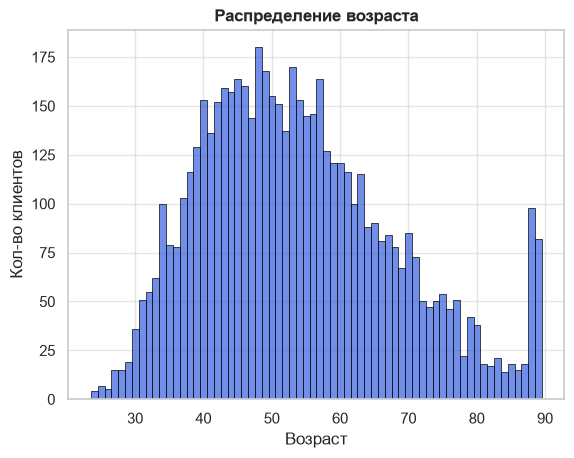

In [19]:
timediff=pd.Series(pd.to_datetime("2025-06-30")-dfClientsRaw["birth_date"])

sns.set_theme(style="whitegrid")
birthDateMin=(timediff.dt.days/365.25).min()
birthDateMax=(timediff.dt.days/365.25).max()
ages=np.arange(birthDateMin,birthDateMax+1,1)
sns.histplot(timediff.dt.days/365.25,bins=ages,  color='royalblue', edgecolor='black')
plt.title('Распределение возраста', fontsize=12, fontweight='bold')
plt.xlabel('Возраст')
plt.ylabel('Кол-во клиентов')
plt.show()

Есть какое-то ограничение по возрасту (т.е. присутствует цензура)

#### 2.3.2 Проверка Transactions

In [20]:
missingTime=~dfTransactionsRaw["txn_datetime"].str.contains(":", na=False)

print("Количество транзакций без корректного времени:",missingTime.sum(),"\n")
print("Процент от всех транзакций:", (missingTime.sum()/len(dfTransactionsRaw)*100).round(2), "\n")
print(dfTransactionsRaw[missingTime].head())

Количество транзакций без корректного времени: 50485 

Процент от всех транзакций: 8.03 

    txn_id client_id txn_datetime   amount currency             category  mcc_code      channel     status
10  100008   C005105   2024-01-01   378.95      RUB             Продукты      5411        Карта    успешно
14  100012   C004000   2024-01-01  4867.26      RUB                  АЗС      5541        Карта    успешно
17  100015   C005594   2024-01-01   130.30      RUB            Транспорт      4111          СБП  отклонено
26  100024   C000575   2024-01-01   138.01      RUB            Транспорт      4111  Онлайн-банк    успешно
29  100027   C005602   2024-01-01  7873.49      RUB  Развлечения и досуг      7832        Карта    успешно


Кол-во неправильно зарегистрированных по времени транзакций 50485 (8% от всех транзакций). Предположительно можно это исправить вставив время, лежащее между соседними транзакциями: так как номер транзакции присваевается в хронологическом порядке.

In [21]:
print("Кол-во уникальных категорий:",len(dfTransactionsRaw["category"].unique()))
print(dfTransactionsRaw["category"].unique(), "\n")
print("Кол-во уникальных кодов категорий:", len(dfTransactionsRaw["mcc_code"].unique()))
print(dfTransactionsRaw["mcc_code"].unique())

Кол-во уникальных категорий: 12
<ArrowStringArray>
[   'Кафе и рестораны',            'Продукты',      'Онлайн-сервисы',                 'АЗС',           'Транспорт',    'Связь и интернет',
 'Развлечения и досуг',              'Аптеки',    'Связь и Интернет',      'Одежда и обувь',    'кафе и рестораны',      'Кафе/рестораны']
Length: 12, dtype: str 

Кол-во уникальных кодов категорий: 9
[5812 5411 5815 5541 4111 4814 7832 5912 5651]


Видно, что количество уникальных категорий не равно 9. Проблема заключается в разном написании одной и той же категории, их надо стандартизировать. А вот с кодами категорий в этом плане всё правильно.

In [22]:
crosstab = pd.crosstab(dfTransactionsRaw['mcc_code'], dfTransactionsRaw['category'])
print(crosstab)

category    АЗС  Аптеки  Кафе и рестораны  Кафе/рестораны  Одежда и обувь  Онлайн-сервисы  Продукты  Развлечения и досуг  Связь и Интернет  Связь и интернет  \
mcc_code                                                                                                                                                       
4111         17      14                12               7              17              11        53                   21                 6                 7   
4814         25      20                21               4              22              17        73                   14             19507             29431   
5411         18      19                16               7              26              13    165214                   20                 5                 8   
5541      57471       9                24              11              18              17        68                   16                 5                10   
5651         25      13                1

Тут видно, что некорректно расставлены коды категорий. Решить проблему можно, определив самый часто встречающийся код для определённой категории (например АЗС соответствует код 5541, потому что он в этой категории встречается чаще остальных).

In [23]:
print(dfTransactionsRaw["status"].unique())

<ArrowStringArray>
['успешно', 'отклонено', 'возврат']
Length: 3, dtype: str


In [24]:
print(dfTransactionsRaw[dfTransactionsRaw["status"]=="возврат"])

        txn_id client_id         txn_datetime   amount currency             category  mcc_code      channel   status
32      100030   C000525  2024-01-01 07:10:53  -465.41      RUB             Продукты      5411        Карта  возврат
53      100051   C004442  2024-01-01 08:33:15 -1243.74      RUB                  АЗС      5541        Токен  возврат
123     100121   C003818  2024-01-01 10:31:13  -147.90      RUB     Связь и интернет      4814        Токен  возврат
489     100486   C005926  2024-01-01 16:22:36  -128.57      RUB             Продукты      5411        Карта  возврат
665     100662   C004030  2024-01-01 20:16:44 -2867.74      RUB       Одежда и обувь      5651        Карта  возврат
...        ...       ...                  ...      ...      ...                  ...       ...          ...      ...
628551  731536   C002184  2025-06-30 15:55:31  -767.31      RUB             Продукты      5411  Онлайн-банк  возврат
628586  731571   C005781  2025-06-30 16:20:14  -437.19      RUB 

Транзакции со статусом возврат соответствует сумма операции $<0$.

In [25]:
print("Количество транзакций со статусом возврат и суммой >= 0: ", ((dfTransactionsRaw["status"]=="возврат") & (dfTransactionsRaw["amount"]>=0)).sum())
print("Количество транзакций НЕ со статусом возврат и суммой <= 0: ", ((dfTransactionsRaw["status"]!="возврат") & (dfTransactionsRaw["amount"]<=0)).sum())

Количество транзакций со статусом возврат и суммой >= 0:  0
Количество транзакций НЕ со статусом возврат и суммой <= 0:  0


Ошибок в заполнении данных по этим критериям нет.

### 2.4. Связь между таблицами

In [26]:
txn_with_clients= dfTransactionsRaw['client_id'].isin(dfClientsRaw['client_id'])
print("Транзакции без соответствующих клиентов:", (~txn_with_clients).sum())

clients_with_txns = dfClientsRaw['client_id'].isin(dfTransactionsRaw['client_id'])
print("Клиенты без единой транзакции:", (~clients_with_txns).sum())

Транзакции без соответствующих клиентов: 27088
Клиенты без единой транзакции: 7


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

Clients: Обнаружено 40 полных дубликатов и 110 дублирующихся client_id. В столбце monthly_income есть аномальные отрицательные значения (-999.0 у 239 клиентов), которые нужно обработать. У 23 клиентов дата последнего входа в приложение (app_last_login) предшествует дате регистрации (registration_date). Пропуски присутствуют в monthly_income (8.92%), app_last_login (37.83%) и satisfaction_score (59.13%).

Transactions: Обнаружено 1278 полных дубликатов и 3000 дубликатов txn_id. У 50485 транзакций (8.03%) время в txn_datetime заполнено некорректно (только дата). Выявлена ошибка в заполнении названий категорий (12 уникальных текстовых названий при 9 уникальных MCC-кодах).

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [27]:
dfClients = dfClientsRaw.copy()


dfClients.loc[dfClients['monthly_income'] < 0, 'monthly_income'] = np.nan
print(dfClients.info())


<class 'pandas.DataFrame'>
RangeIndex: 5715 entries, 0 to 5714
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5715 non-null   str           
 1   birth_date          5715 non-null   datetime64[us]
 2   gender              5715 non-null   str           
 3   city                5715 non-null   str           
 4   segment             5715 non-null   str           
 5   loyalty_tier        5715 non-null   str           
 6   card_type           5715 non-null   str           
 7   registration_date   5715 non-null   datetime64[us]
 8   card_open_date      5715 non-null   datetime64[us]
 9   income_source       5715 non-null   str           
 10  monthly_income      5155 non-null   float64       
 11  has_mobile_app      5715 non-null   str           
 12  app_last_login      3553 non-null   datetime64[us]
 13  satisfaction_score  2336 non-null   float64       
 14  bra

In [28]:
dfTransactions = dfTransactionsRaw.copy()
dfTransactions['txn_datetime'] = pd.to_datetime(dfTransactions['txn_datetime'], errors='coerce')
print(dfTransactions.info())

<class 'pandas.DataFrame'>
RangeIndex: 628989 entries, 0 to 628988
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        628989 non-null  int64         
 1   client_id     628989 non-null  str           
 2   txn_datetime  578504 non-null  datetime64[us]
 3   amount        628989 non-null  float64       
 4   currency      628989 non-null  str           
 5   category      628989 non-null  str           
 6   mcc_code      628989 non-null  int64         
 7   channel       628989 non-null  str           
 8   status        628989 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 77.0 MB
None


### 3.2. Категориальные признаки

In [29]:
CATEGORIAL_COLS=["gender", "segment", "loyalty_tier", "card_type",
                 "income_source", "has_mobile_app","satisfaction_score","marketing_opt_in"]

LOYALTY_TIER_GRADE=[ "Базовый", "Серебро", "Золото","Платина"]

SATISFACTION_SCORE_GRADE=[1.,2.,3.,4.,5]

dfClients['income_source']=dfClients['income_source'].replace('Не указан', np.nan)

dfClients=dfClients.assign(
    gender=dfClients["gender"].astype('category'),
    segment=dfClients["segment"].astype('category'),
    loyalty_tier=pd.Categorical(dfClients["loyalty_tier"],categories=LOYALTY_TIER_GRADE, ordered=True ),
    card_type=dfClients["card_type"].astype('category'),
    income_source=dfClients["income_source"].astype('category'),
    has_mobile_app=dfClients["has_mobile_app"].map({"Да":True, "Нет":False}),
    satisfaction_score=pd.Categorical(dfClients["satisfaction_score"] ,ordered=True ),
    marketing_opt_in=dfClients["marketing_opt_in"].map({"Да":True, "Нет":False})
)



dfClients['city'] = dfClients['city'].astype(str).str.strip().str.lower()
dfClients['city'] = dfClients['city'].str.replace(r'^(г\.|г\s+|город\s+)', '', regex=True)
dfClients['city'] = dfClients['city'].astype(str).str.strip().str.lower()
dfClients['city'] = dfClients['city'].str.capitalize()

city_corrections = {
    'Санкт петербург': 'Санкт-Петербург',
    'Санкт-петербург': 'Санкт-Петербург',
    'Спб': 'Санкт-Петербург',
    'Мск': 'Москва',
    'Н. новгород':'Нижний новгород'
}
dfClients['city'] = dfClients['city'].replace(city_corrections)

print("Уникальные города после обрабтки:")
print(dfClients['city'].unique(),"\n")



dfClients.info()



Уникальные города после обрабтки:
<ArrowStringArray>
['Москва', 'Нижний новгород', 'Екатеринбург', 'Санкт-Петербург', 'Новосибирск', 'Казань']
Length: 6, dtype: str 

<class 'pandas.DataFrame'>
RangeIndex: 5715 entries, 0 to 5714
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5715 non-null   str           
 1   birth_date          5715 non-null   datetime64[us]
 2   gender              5715 non-null   category      
 3   city                5715 non-null   str           
 4   segment             5715 non-null   category      
 5   loyalty_tier        5715 non-null   category      
 6   card_type           5715 non-null   category      
 7   registration_date   5715 non-null   datetime64[us]
 8   card_open_date      5715 non-null   datetime64[us]
 9   income_source       4194 non-null   category      
 10  monthly_income      5155 non-null   float64       
 11  has_

In [30]:


dfTransactions['category'] = dfTransactions['category'].str.strip().str.lower()
dfTransactions['category'] = dfTransactions['category'].str.capitalize()
mcc_to_category = dfTransactions.groupby('mcc_code')['category'].agg(lambda x: x.mode()[0]).to_dict()
dfTransactions['category'] = dfTransactions['mcc_code'].map(mcc_to_category)

print("Уникальные категории после обработки:", dfTransactions['category'].unique())

dfTransactions.info()

Уникальные категории после обработки: <ArrowStringArray>
['Кафе и рестораны', 'Продукты', 'Онлайн-сервисы', 'Азс', 'Транспорт', 'Связь и интернет', 'Развлечения и досуг', 'Аптеки', 'Одежда и обувь']
Length: 9, dtype: str
<class 'pandas.DataFrame'>
RangeIndex: 628989 entries, 0 to 628988
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        628989 non-null  int64         
 1   client_id     628989 non-null  str           
 2   txn_datetime  578504 non-null  datetime64[us]
 3   amount        628989 non-null  float64       
 4   currency      628989 non-null  str           
 5   category      628989 non-null  str           
 6   mcc_code      628989 non-null  int64         
 7   channel       628989 non-null  str           
 8   status        628989 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 77.1 MB


In [31]:
CATEGORIAL_COLS_TRANSACTIONS=["currency", "category" , "channel", "status"]

dfTransactions=dfTransactions.assign(
    currency=dfTransactions['currency'].astype('category'),
    category=dfTransactions["category"].astype("category"),
    channel=dfTransactions["channel"].astype("category"),
    status=dfTransactions["status"].astype("category")
)

print(dfTransactions.info())


<class 'pandas.DataFrame'>
RangeIndex: 628989 entries, 0 to 628988
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        628989 non-null  int64         
 1   client_id     628989 non-null  str           
 2   txn_datetime  578504 non-null  datetime64[us]
 3   amount        628989 non-null  float64       
 4   currency      628989 non-null  category      
 5   category      628989 non-null  category      
 6   mcc_code      628989 non-null  int64         
 7   channel       628989 non-null  category      
 8   status        628989 non-null  category      
dtypes: category(4), datetime64[us](1), float64(1), int64(2), str(1)
memory usage: 30.6 MB
None


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [32]:
missingIncomeVal=len( dfClients[ (dfClients["income_source"].isna()) & (dfClients["monthly_income"].isna())] )
print("Процент незаполненных monthly_income полей среди клиентов с незаполненным income_source:", round( 100*missingIncomeVal
        / len( dfClients[dfClients["income_source"].isna()] ), 2))

Процент незаполненных monthly_income полей среди клиентов с незаполненным income_source: 25.9


In [33]:

print("Доля пропусков до обработки:")
print((dfClients.isna().mean() * 100).round(2))

invalid_income_mask = dfClients['monthly_income'] < 19522.8
dfClients.loc[invalid_income_mask, 'monthly_income'] = np.nan

income_mask = dfClients['monthly_income'].isna() & dfClients['income_source'].notna()

median_l1 = dfClients.groupby(['segment', 'card_type', 'city', 'loyalty_tier'])['monthly_income'].transform('median')
dfClients.loc[income_mask, 'monthly_income'] = dfClients.loc[income_mask, 'monthly_income'].fillna(median_l1[income_mask])

print("\nПропуски после обработки:")
print(dfClients[['monthly_income', 'app_last_login', 'satisfaction_score']].isna().sum())

Доля пропусков до обработки:
client_id              0.00
birth_date             0.00
gender                 0.00
city                   0.00
segment                0.00
loyalty_tier           0.00
card_type              0.00
registration_date      0.00
card_open_date         0.00
income_source         26.61
monthly_income         9.80
has_mobile_app         0.00
app_last_login        37.83
satisfaction_score    59.13
branch_code            0.00
marketing_opt_in       0.00
dtype: float64

Пропуски после обработки:
monthly_income         440
app_last_login        2162
satisfaction_score    3379
dtype: int64


Неизвестные зарплаты будем заполнять медианным значением клиентов из одного города, сегмента, уровня лояльности и одного типа карты. У клиентов с не указанным источником зарплаты monthly_income лучше оставить пропущенными, так как есть предположение, что это признак малого дохода. (Проверять буду далее)

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

Нижняя граница IQR: -27725.0, Верхняя граница IQR: 193675.0
Количество выбросов по методу IQR: 422

Самые высокие доходы в датасете:
4908    932000.0
3268    919700.0
3105    885000.0
3449    866700.0
4925    852100.0
4062    812100.0
1872    784700.0
3995    760500.0
451     743900.0
3520    741300.0
Name: monthly_income, dtype: float64


Text(193675.0, -0.35, 'Q3 + 1.5·IQR = 193675')

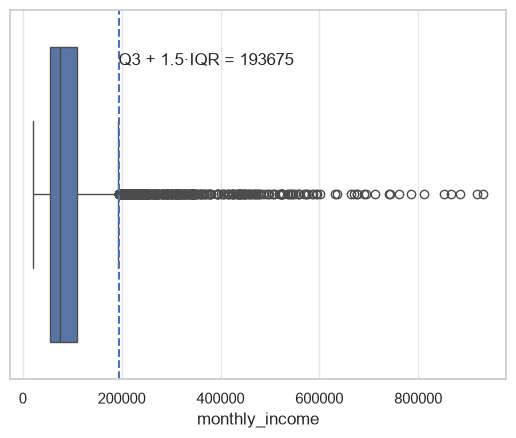

In [34]:
Q=dfClients['monthly_income'].dropna()
Q1 = dfClients['monthly_income'].quantile(0.25)
Q3 = dfClients['monthly_income'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = dfClients[(dfClients['monthly_income'] < lower_bound) | (dfClients['monthly_income'] > upper_bound)]
print(f"Нижняя граница IQR: {lower_bound}, Верхняя граница IQR: {upper_bound}")
print(f"Количество выбросов по методу IQR: {len(outliers_iqr)}")


print("\nСамые высокие доходы в датасете:")
print(dfClients['monthly_income'].nlargest(10))

sns.set_theme(style="whitegrid")
sns.boxplot(x=Q)
plt.axvline(upper_bound,  ls="--")
plt.annotate(f"Q3 + 1.5·IQR = {upper_bound:.0f}", xy=(upper_bound, -0.35))
# plt.set_title(f"Количество: {(Q > upper_bound).sum()} строк выше границы IQR")
# plt.set_xlabel("Количество единиц в строке заказа, шт.")
# Если требуется ограничить аномально гигантские выбросы (например, выше 99.5 перцентиля):
# cap_value = dfClients['monthly_income'].quantile(0.995)
# dfClients['monthly_income'] = dfClients['monthly_income'].clip(upper=cap_value)

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [35]:
step_raw = len(dfTransactions)

dfTransactionsFiltered = dfTransactions.drop_duplicates(subset=['txn_id'], keep='first').copy()
step_dedup = len(dfTransactionsFiltered)

valid_statuses = ['успешно', 'возврат']
dfTransactionsFiltered = dfTransactionsFiltered[dfTransactionsFiltered['status'].isin(valid_statuses)]
step_status = len(dfTransactionsFiltered)

# Формируем и выводим таблицу-воронку
funnel_transactions = pd.DataFrame({
    'Этап воронки': [
        '1. Сырые данные на входе',
        '2. После удаления дубликатов txn_id',
        '3. После отбора успешных транзакций и возвратов'
    ],
    'Строк осталось': [step_raw, step_dedup, step_status],
    'Отсеяно строк': [0, step_raw - step_dedup, step_dedup - step_status],
    '% от исходного': [
        100.0,
        round(step_dedup / step_raw * 100, 2),
        round(step_status / step_raw * 100, 2)
    ]
})

print("Воронка фильтрации транзакций:")
display(funnel_transactions)

Воронка фильтрации транзакций:


,Этап воронки,Строк осталось,Отсеяно строк,% от исходного
0,1. Сырые данные на входе,628989,0,100.00
1,2. После удаления дубликатов txn_id,627489,1500,99.76
2,3. После отбора успешных транзакций и возвратов,615049,12440,97.78


 Убираются дубликаты tnx_id (удаляется 1500 строк,  для уникальности каждой транзакции).  Также убираются транзакции со статусом 'отклонено'. Поскольку отклоненные платежи не завершились переводом средств, их учет исказил бы активность клиента, в расчет берутся только успешные операции и возвраты.

In [36]:
initial_rows = len(dfClientsRaw)
dfClientsRaw = dfClientsRaw.drop_duplicates(subset=['client_id'], keep='first').copy()
print(f"Удалено дубликатов по client_id: {initial_rows - len(dfClientsRaw)}")

Удалено дубликатов по client_id: 55


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [37]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [38]:
log_data = [
    {
        "field": "client_id",
        "issue": "Дублирующиеся идентификаторы клиентов и полные дубли",
        "scope": "clients.csv",
        "n_rows": int(dfClientsRaw.duplicated(subset=['client_id']).sum()),
        "value_before": "Дублирующиеся строки по client_id",
        "action": "Удаление дубликатов (drop_duplicates)",
        "value_after": "Уникальные client_id",
        "rationale": "Обеспечение уникальности записей клиентов для корректного слияния таблиц"
    },
    {
        "field": "monthly_income",
        "issue": "Отрицательные аномальные значения (-999.0)",
        "scope": "clients.csv",
        "n_rows": int((dfClientsRaw['monthly_income'] < 0).sum()),
        "value_before": "< 0 (например, -999)",
        "action": "Замена на NaN",
        "value_after": "NaN",
        "rationale": "Отрицательный доход экономически невозможен"
    },
    {
        "field": "monthly_income",
        "issue": "Пропущенные значения дохода",
        "scope": "clients.csv",
        "n_rows": int(dfClients['monthly_income'].isna().sum()),
        "value_before": "NaN",
        "action": "Частичная импутация медианой по группам; остальное было оставлено",
        "value_after": "Заполнено для части строк, остальное NaN",
        "rationale": "Заполнение пропусков для релевантных групп, остальные пропуски были оставлены"
    },
    {
        "field": "monthly_income",
        "issue": "Выбросы (аномально высокие доходы по IQR)",
        "scope": "clients.csv",
        "n_rows": 423,
        "value_before": "Значения выше верхнего квартиля IQR",
        "action": "Было оставлено без изменений",
        "value_after": "Исходные высокие значения",
        "rationale": "Выбросы не удалялись и не ограничивались, так как могут отражать реальные премиальные сегменты"
    },
    {
        "field": "income_source",
        "issue": "Неинформативное текстовое значение 'Не указан'",
        "scope": "clients.csv",
        "n_rows": int((dfClientsRaw['income_source'] == 'Не указан').sum()),
        "value_before": "'Не указан'",
        "action": "Замена на NaN, пропуски были оставлены",
        "value_after": "NaN",
        "rationale": "Перевод неинформативной метки в стандартный пропуск"
    },
    {
        "field": "satisfaction_score",
        "issue": "Пропущенные значения (NaN) в оценке удовлетворенности (~59%)",
        "scope": "clients.csv",
        "n_rows": int(dfClientsRaw['satisfaction_score'].isna().sum()),
        "value_before": "NaN",
        "action": "Было оставлено без изменений",
        "value_after": "NaN",
        "rationale": "Пропуски не заполнялись и были оставлены как есть"
    },
    {
        "field": "app_last_login",
        "issue": "Пропуски и логические нестыковки с датой регистрации",
        "scope": "clients.csv",
        "n_rows": int(dfClientsRaw['app_last_login'].isna().sum()),
        "value_before": "NaT / некорректные даты",
        "action": "Было оставлено без изменений",
        "value_after": "Исходное состояние",
        "rationale": "Данные по последнему входу были оставлены как есть"
    },
    {
        "field": "city",
        "issue": "Разнобой в наименованиях городов (регистр, префиксы, опечатки)",
        "scope": "clients.csv",
        "n_rows": len(dfClientsRaw),
        "value_before": "г. Москва, МОСКВА, спб, Н. новгород",
        "action": "Нормализация регистра, удаление префиксов, маппинг синонимов",
        "value_after": "Москва, Санкт-Петербург, Нижний Новгород и др.",
        "rationale": "Приведение к единому стандарту для корректной группировки"
    },
    {
        "field": "txn_datetime",
        "issue": "Строковый формат даты и времени, отсутствие времени у части транзакций",
        "scope": "transactions.csv",
        "n_rows": int(dfTransactionsRaw['txn_datetime'].notna().sum()),
        "value_before": "Строковый тип / неполное время",
        "action": "Конвертация в datetime (errors='coerce'); неполные даты/время были оставлены как NaT",
        "value_after": "datetime64[ns] / NaT",
        "rationale": "Перевод в datetime формат, некорректные строки приведены к NaT и оставлены"
    },
    {
        "field": "category",
        "issue": "Несогласованность текстовых категорий и MCC-кодов",
        "scope": "transactions.csv",
        "n_rows": len(dfTransactionsRaw),
        "value_before": "кафе и рестораны, Кафе/рестораны, Связь и интернет",
        "action": "Приведение к единому стандарту по моде MCC-кода, strip, capitalize",
        "value_after": "Стандартизированные названия категорий",
        "rationale": "Устранение дублирования категорий из-за опечаток и регистра"
    },
    {
        "field": "txn_id",
        "issue": "Дубликаты идентификаторов транзакций и полные дубли строк",
        "scope": "transactions.csv",
        "n_rows": int(dfTransactionsRaw['txn_id'].duplicated().sum()),
        "value_before": "Дублирующиеся строки и txn_id",
        "action": "Удаление дубликатов (drop_duplicates)",
        "value_after": "Уникальные строки по txn_id",
        "rationale": "Обеспечение корректности единицы наблюдения в таблице транзакций"
    },
    {
        "field": "status",
        "issue": "Наличие отклоненных транзакций в сырых данных",
        "scope": "transactions.csv",
        "n_rows": int((dfTransactionsRaw['status'] == 'отклонено').sum()),
        "value_before": "'отклонено'",
        "action": "Фильтрация датасета (оставлены 'успешно' и 'возврат')",
        "value_after": "'успешно', 'возврат'",
        "rationale": "Исключение неудачных операций, не влияющих на реальный денежный оборот"
    }
]

cleaning_log = pd.DataFrame(log_data)
display(cleaning_log)

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,client_id,Дублирующиеся идентификаторы клиентов и полные...,clients.csv,0,Дублирующиеся строки по client_id,Удаление дубликатов (drop_duplicates),Уникальные client_id,Обеспечение уникальности записей клиентов для ...
1,monthly_income,Отрицательные аномальные значения (-999.0),clients.csv,48,"< 0 (например, -999)",Замена на NaN,NaN,Отрицательный доход экономически невозможен
2,monthly_income,Пропущенные значения дохода,clients.csv,440,NaN,Частичная импутация медианой по группам; остал...,"Заполнено для части строк, остальное NaN","Заполнение пропусков для релевантных групп, ос..."
3,monthly_income,Выбросы (аномально высокие доходы по IQR),clients.csv,423,Значения выше верхнего квартиля IQR,Было оставлено без изменений,Исходные высокие значения,"Выбросы не удалялись и не ограничивались, так ..."
4,income_source,Неинформативное текстовое значение 'Не указан',clients.csv,1503,'Не указан',"Замена на NaN, пропуски были оставлены",NaN,Перевод неинформативной метки в стандартный пр...
5,satisfaction_score,Пропущенные значения (NaN) в оценке удовлетвор...,clients.csv,3349,NaN,Было оставлено без изменений,NaN,Пропуски не заполнялись и были оставлены как есть
6,app_last_login,Пропуски и логические нестыковки с датой регис...,clients.csv,2149,NaT / некорректные даты,Было оставлено без изменений,Исходное состояние,Данные по последнему входу были оставлены как ...
7,city,"Разнобой в наименованиях городов (регистр, пре...",clients.csv,5660,"г. Москва, МОСКВА, спб, Н. новгород","Нормализация регистра, удаление префиксов, мап...","Москва, Санкт-Петербург, Нижний Новгород и др.",Приведение к единому стандарту для корректной ...
8,txn_datetime,"Строковый формат даты и времени, отсутствие вр...",transactions.csv,628989,Строковый тип / неполное время,Конвертация в datetime (errors='coerce'); непо...,datetime64[ns] / NaT,"Перевод в datetime формат, некорректные строки..."
9,category,Несогласованность текстовых категорий и MCC-кодов,transactions.csv,628989,"кафе и рестораны, Кафе/рестораны, Связь и инте...",Приведение к единому стандарту по моде MCC-код...,Стандартизированные названия категорий,Устранение дублирования категорий из-за опечат...


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

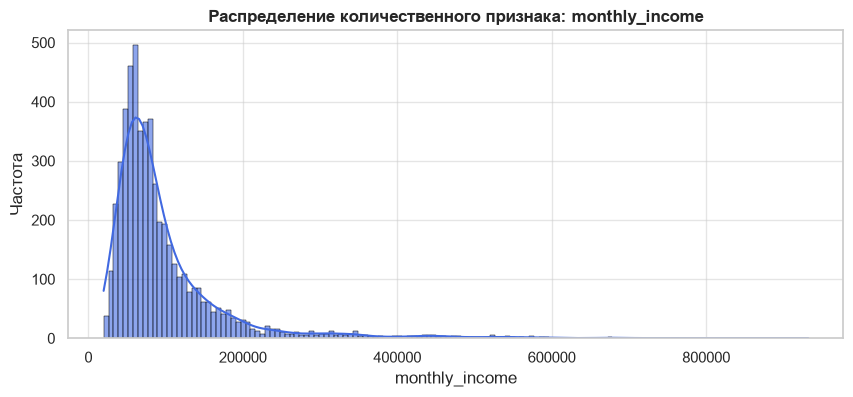

In [39]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 4))
sns.histplot(dfClients['monthly_income'].dropna(), kde=True, color='royalblue', edgecolor='black', alpha=0.6)
plt.title('Распределение количественного признака: monthly_income', fontsize=12, fontweight='bold')
plt.xlabel('monthly_income')
plt.ylabel('Частота')
plt.show()



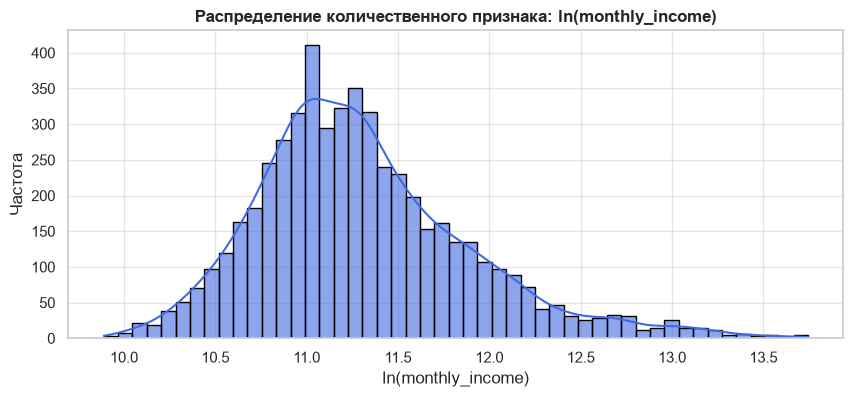

In [40]:
sns.set_theme(style="whitegrid")
log_scale=np.log(dfClients['monthly_income'])
plt.figure(figsize=(10, 4))
sns.histplot(log_scale.dropna(), kde=True, color='royalblue', edgecolor='black', alpha=0.6)
plt.title('Распределение количественного признака: ln(monthly_income)', fontsize=12, fontweight='bold')
plt.xlabel('ln(monthly_income)')
plt.ylabel('Частота')
plt.show()

В изначальных данных о зарплате наблюдается тяжёлый хвост справа, чтобы приблизить данное распределение к нормальному, значения зарплат модно прологарифмировать, чтобы сжать правый хвост.

### 5.2. Частотные характеристики категориальных признаков

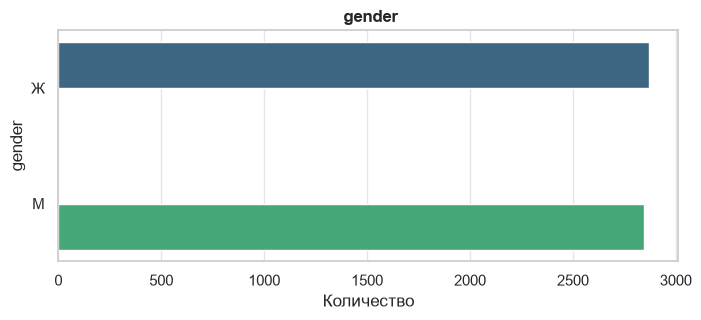

In [41]:
plt.figure(figsize=(8, 3))
sns.countplot(data=dfClients, y='gender', palette='viridis', hue='gender', legend=False)
plt.title(' gender', fontsize=12, fontweight='bold')
plt.xlabel('Количество')
plt.ylabel('gender')
plt.show()



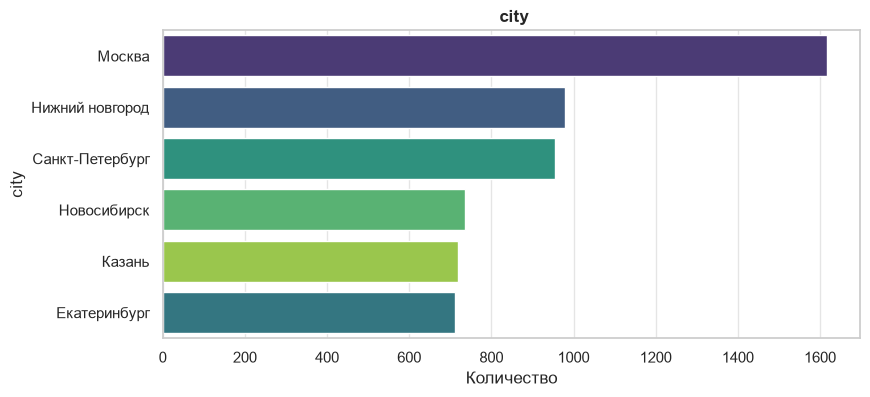

In [42]:
plt.figure(figsize=(9, 4))
sns.countplot(data=dfClients, y='city', order=dfClients['city'].value_counts().index, palette='viridis', hue='city', legend=False)
plt.title(' city', fontsize=12, fontweight='bold')
plt.xlabel('Количество')
plt.ylabel('city')
plt.show()


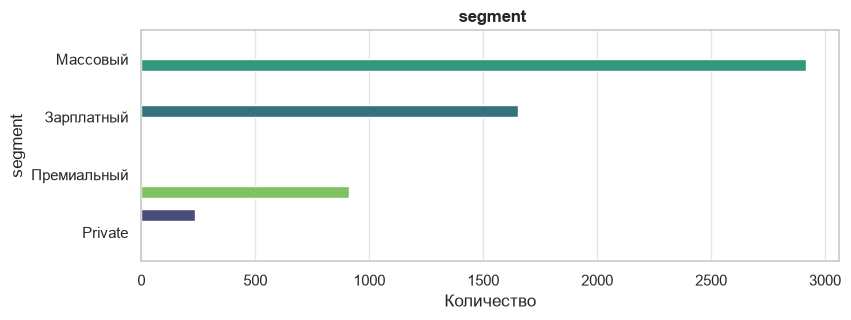

In [43]:
plt.figure(figsize=(9, 3))
sns.countplot(data=dfClients, y='segment', order=dfClients['segment'].value_counts().index, palette='viridis', hue='segment', legend=False)
plt.title(' segment', fontsize=12, fontweight='bold')
plt.xlabel('Количество')
plt.ylabel('segment')
plt.show()


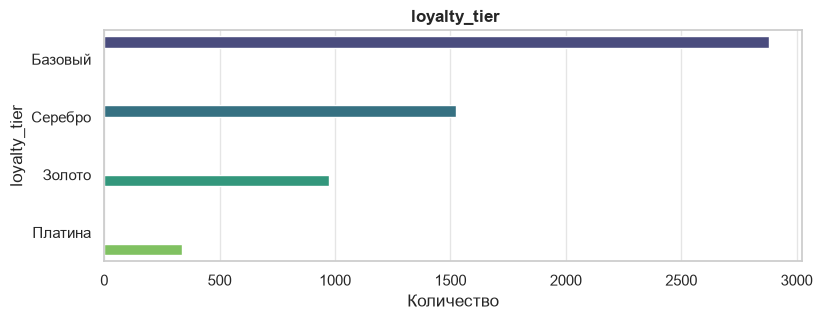

In [44]:
plt.figure(figsize=(9, 3))
sns.countplot(data=dfClients, y='loyalty_tier', order=dfClients['loyalty_tier'].value_counts().index, palette='viridis', hue='loyalty_tier', legend=False)
plt.title(' loyalty_tier', fontsize=12, fontweight='bold')
plt.xlabel('Количество')
plt.ylabel('loyalty_tier')
plt.show()


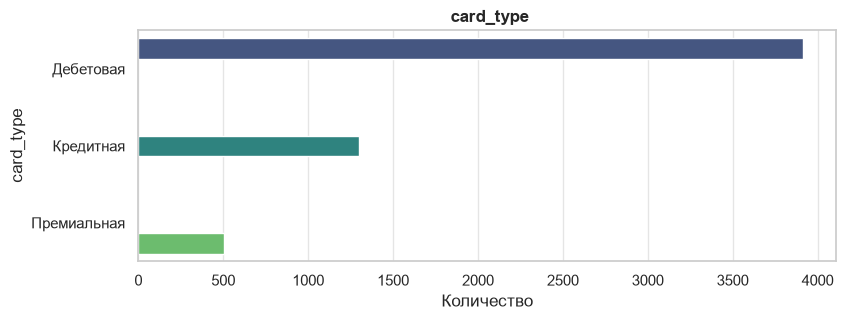

In [45]:
plt.figure(figsize=(9, 3))
sns.countplot(data=dfClients, y='card_type', order=dfClients['card_type'].value_counts().index, palette='viridis', hue='card_type', legend=False)
plt.title(' card_type', fontsize=12, fontweight='bold')
plt.xlabel('Количество')
plt.ylabel('card_type')
plt.show()


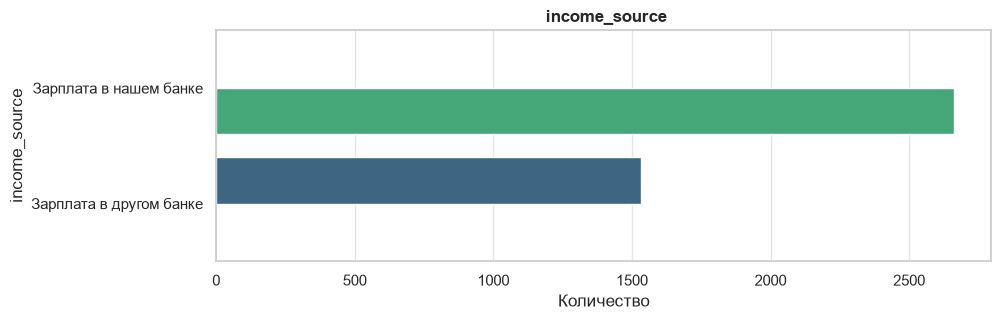

In [46]:
plt.figure(figsize=(10, 3))
sns.countplot(data=dfClients, y='income_source', order=dfClients['income_source'].value_counts().index, palette='viridis', hue='income_source', legend=False)
plt.title(' income_source', fontsize=12, fontweight='bold')
plt.xlabel('Количество')
plt.ylabel('income_source')
plt.show()


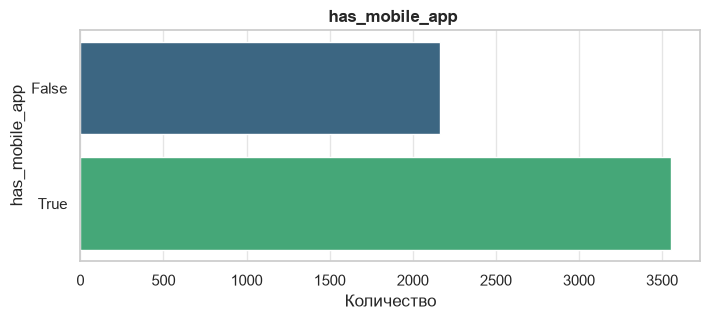

In [47]:
plt.figure(figsize=(8, 3))
sns.countplot(data=dfClients, y='has_mobile_app', palette='viridis', hue='has_mobile_app', legend=False)
plt.title(' has_mobile_app', fontsize=12, fontweight='bold')
plt.xlabel('Количество')
plt.ylabel('has_mobile_app')
plt.show()


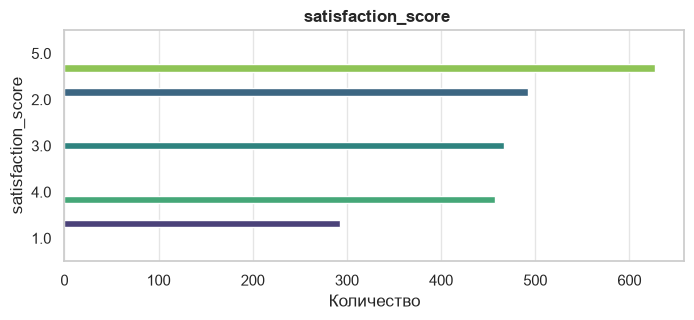

In [48]:
plt.figure(figsize=(8, 3))
sns.countplot(data=dfClients, y='satisfaction_score', order=dfClients['satisfaction_score'].value_counts().index, palette='viridis', hue='satisfaction_score', legend=False)
plt.title(' satisfaction_score', fontsize=12, fontweight='bold')
plt.xlabel('Количество')
plt.ylabel('satisfaction_score')
plt.show()



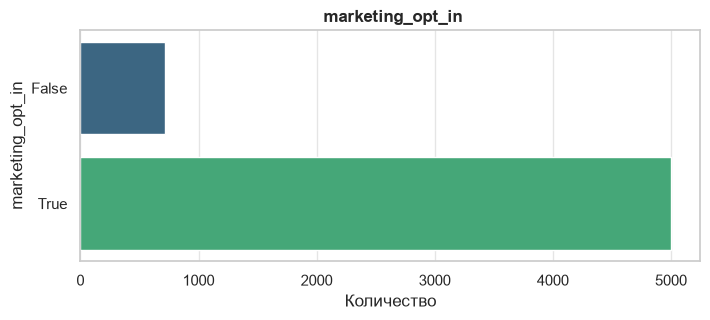

In [49]:
plt.figure(figsize=(8, 3))
sns.countplot(data=dfClients, y='marketing_opt_in', palette='viridis', hue='marketing_opt_in', legend=False)
plt.title(' marketing_opt_in', fontsize=12, fontweight='bold')
plt.xlabel('Количество')
plt.ylabel('marketing_opt_in')
plt.show()

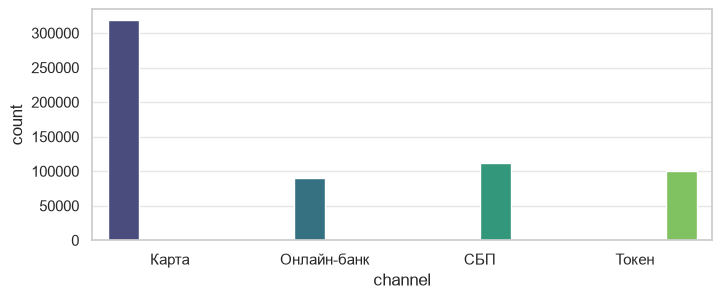

In [50]:
plt.figure(figsize=(8, 3))
channel=dfTransactions[dfTransactions["status"]!="возврат"]
sns.countplot(data=channel, x="channel", palette='viridis', hue="channel", legend=False)
plt.show()

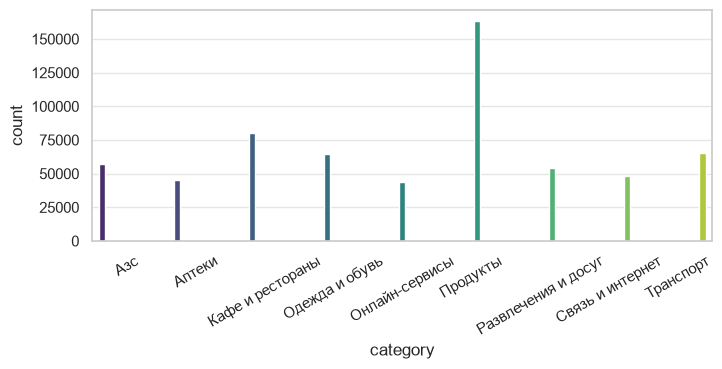

In [51]:
plt.figure(figsize=(8, 3))
channel=dfTransactions[dfTransactions["status"]!="возврат"]
sns.countplot(data=channel, x="category", palette='viridis', hue="category", legend=False)
plt.xticks(rotation=30)
plt.show()

### 5.3. Динамика по месяцам

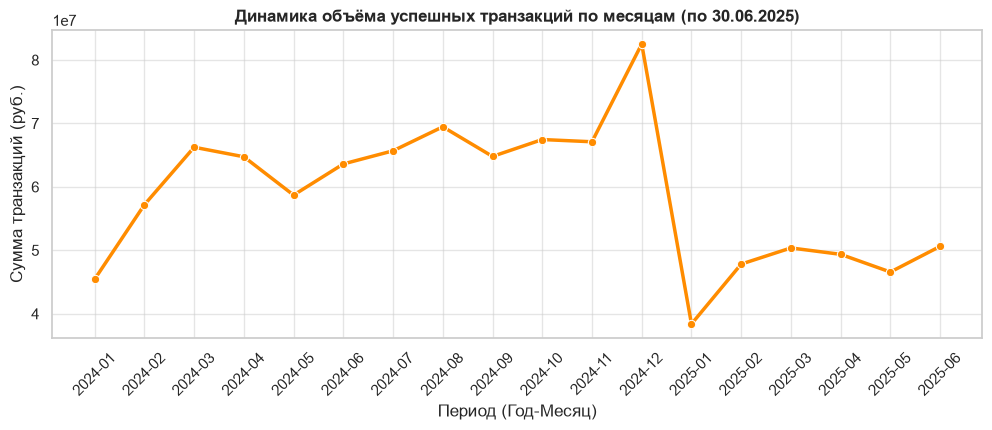

In [52]:

dfTransactions['txn_datetime'] = pd.to_datetime(dfTransactions['txn_datetime'], errors='coerce')


df_filtered = dfTransactions[
    (dfTransactions['status'] == 'успешно') &
    (dfTransactions['txn_datetime'] <= '2025-06-30') &(dfTransactions['txn_datetime'] >= '2024-01-01')
].copy()

df_filtered['year_month'] = df_filtered['txn_datetime'].dt.to_period('M')

monthly_dynamics = df_filtered.groupby('year_month')['amount'].sum().reset_index()
monthly_dynamics['year_month'] = monthly_dynamics['year_month'].astype(str)

plt.figure(figsize=(12, 4))
sns.lineplot(data=monthly_dynamics, x='year_month', y='amount', marker='o', color='darkorange', linewidth=2.5)
plt.title('Динамика объёма успешных транзакций по месяцам (по 30.06.2025)', fontsize=12, fontweight='bold')
plt.xlabel('Период (Год-Месяц)')
plt.ylabel('Сумма транзакций (руб.)')
plt.xticks(rotation=45)
plt.show()

Наблюдается резкий спад объёма транзакций в начале 2025 года.

### 5.4. Разрезы и связи между признаками

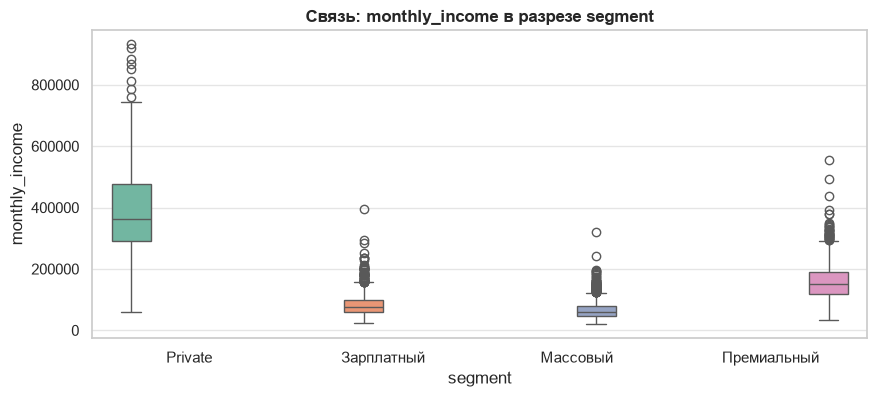

In [53]:

plt.figure(figsize=(10, 4))
sns.boxplot(data=dfClients, x='segment', y='monthly_income', palette='Set2', hue='segment', legend=False)
plt.title('Связь: monthly_income в разрезе segment', fontsize=12, fontweight='bold')
plt.xlabel('segment')
plt.ylabel('monthly_income')
plt.show()


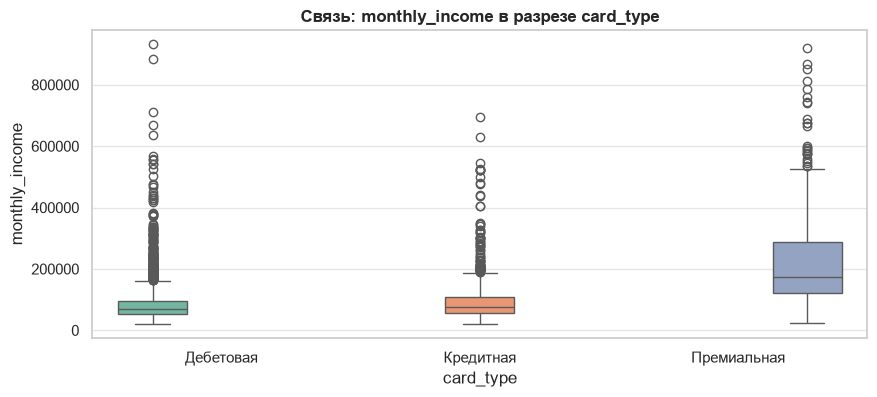

In [54]:

plt.figure(figsize=(10, 4))
sns.boxplot(data=dfClients, x='card_type', y='monthly_income', palette='Set2', hue='card_type', legend=False)
plt.title('Связь: monthly_income в разрезе card_type', fontsize=12, fontweight='bold')
plt.xlabel('card_type')
plt.ylabel('monthly_income')
plt.show()


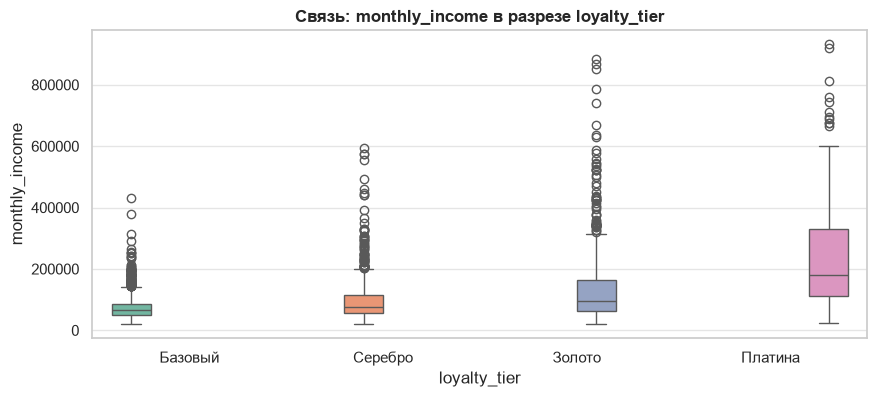

In [55]:

plt.figure(figsize=(10, 4))
sns.boxplot(data=dfClients, x='loyalty_tier', y='monthly_income', palette='Set2', hue='loyalty_tier', legend=False)
plt.title('Связь: monthly_income в разрезе loyalty_tier', fontsize=12, fontweight='bold')
plt.xlabel('loyalty_tier')
plt.ylabel('monthly_income')
plt.show()

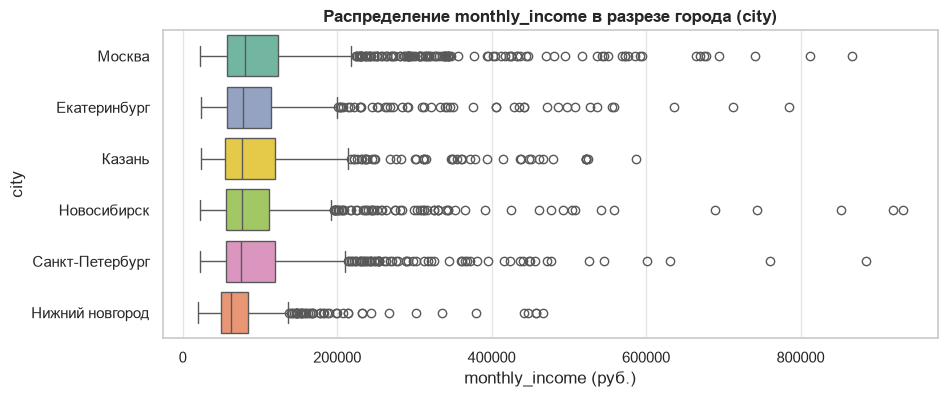

In [56]:
plt.figure(figsize=(10, max(4, len(dfClients['city'].dropna().unique()) * 0.4)))

city_order = dfClients.groupby('city', observed=True)['monthly_income'].median().sort_values(ascending=False).index

sns.boxplot(
    data=dfClients,
    x='monthly_income',
    y='city',
    order=city_order,
    palette='Set2',
    hue='city',
    legend=False,
)
plt.title('Распределение monthly_income в разрезе города (city)', fontsize=12, fontweight='bold')
plt.xlabel('monthly_income (руб.)')
plt.ylabel('city')
plt.show()

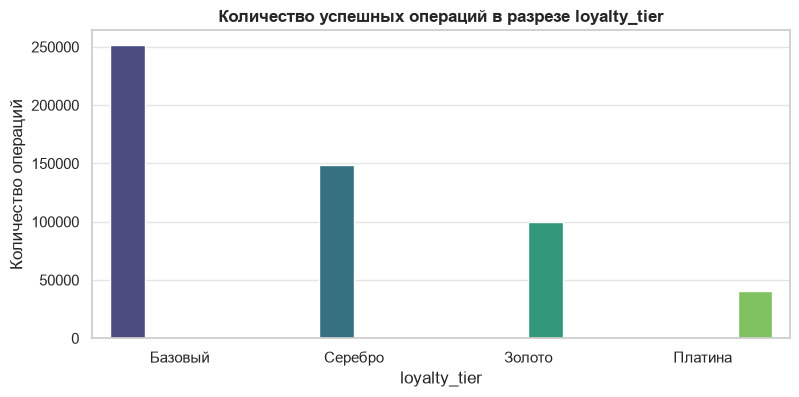

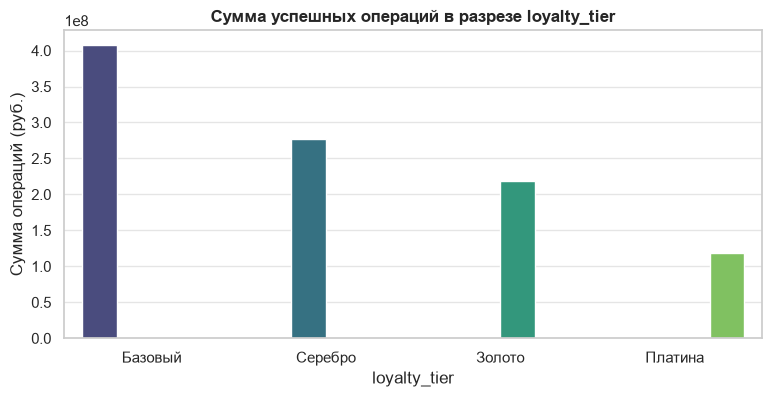

In [57]:
df_merged = dfTransactions[
    (dfTransactions['status'] == 'успешно') &
    (dfTransactions['txn_datetime'] <= '2025-06-30')
].merge(dfClients, on='client_id', how='inner')

loyalty_agg = df_merged.groupby('loyalty_tier').agg(
    txn_count=('amount', 'count'),
    txn_sum=('amount', 'sum')
).reset_index()

plt.figure(figsize=(9, 4))
sns.barplot(data=loyalty_agg, x='loyalty_tier', y='txn_count', palette='viridis', hue='loyalty_tier', legend=False)
plt.title('Количество успешных операций в разрезе loyalty_tier', fontsize=12, fontweight='bold')
plt.xlabel('loyalty_tier')
plt.ylabel('Количество операций')
plt.show()

plt.figure(figsize=(9, 4))
sns.barplot(data=loyalty_agg, x='loyalty_tier', y='txn_sum', palette='viridis', hue='loyalty_tier', legend=False)
plt.title('Сумма успешных операций в разрезе loyalty_tier', fontsize=12, fontweight='bold')
plt.xlabel('loyalty_tier')
plt.ylabel('Сумма операций (руб.)')
plt.show()



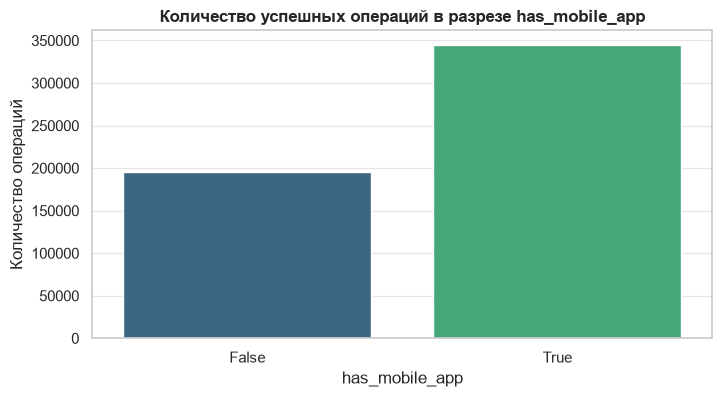

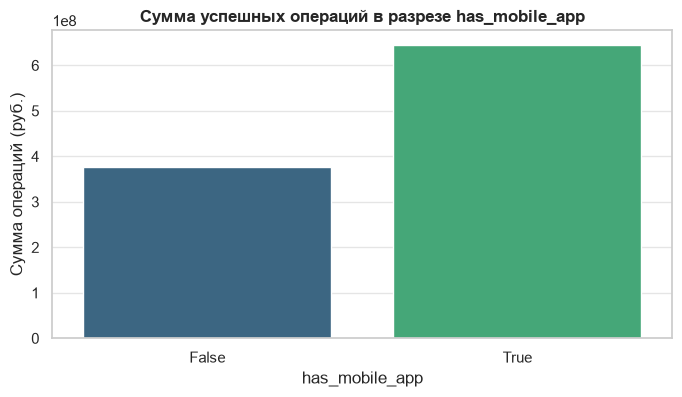

In [58]:

app_agg = df_merged.groupby('has_mobile_app').agg(
    txn_count=('amount', 'count'),
    txn_sum=('amount', 'sum')
).reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=app_agg, x='has_mobile_app', y='txn_count', palette='viridis', hue='has_mobile_app', legend=False)
plt.title('Количество успешных операций в разрезе has_mobile_app', fontsize=12, fontweight='bold')
plt.xlabel('has_mobile_app')
plt.ylabel('Количество операций')
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(data=app_agg, x='has_mobile_app', y='txn_sum', palette='viridis', hue='has_mobile_app', legend=False)
plt.title('Сумма успешных операций в разрезе has_mobile_app', fontsize=12, fontweight='bold')
plt.xlabel('has_mobile_app')
plt.ylabel('Сумма операций (руб.)')
plt.show()

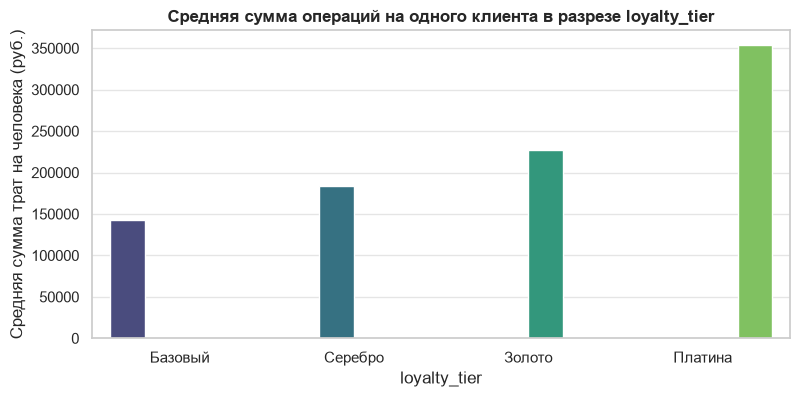

In [59]:
df_merged = dfTransactions[
    (dfTransactions['status'] == 'успешно') &
    (dfTransactions['txn_datetime'] <= '2025-06-30')
].merge(dfClients[['client_id', 'loyalty_tier']], on='client_id', how='inner')

client_totals = df_merged.groupby(['client_id', 'loyalty_tier'], observed=True)['amount'].sum().reset_index()


avg_spend_per_client = client_totals.groupby('loyalty_tier', observed=True)['amount'].mean().reset_index()

plt.figure(figsize=(9, 4))
sns.barplot(data=avg_spend_per_client,x='loyalty_tier',y='amount',palette='viridis',hue='loyalty_tier',legend=False)
plt.title('Средняя сумма операций на одного клиента в разрезе loyalty_tier', fontsize=12, fontweight='bold')
plt.xlabel('loyalty_tier')
plt.ylabel('Средняя сумма трат на человека (руб.)')
plt.show()

Можно сделать предположение, что loyalty_tier зависит от общей суммы транзакций.

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

За метрику активности будем брать среднюю сумму транзакций за определённый промежуток времени. Для определения спада активности будем сравнивать активность с 2024-01-01 по 2024-12-31 с активностью за промежуток времени с 2025-01-01 по 2025-06-30. Возникает проблема, если сумма транзакций в начале периода была высокой, а затем снизилась и осталась постоянной, то по среднему будет трудно заметить это. Чтобы решить эту проблему, надо определить начался ли спад до 2025-01-01: считаем активность за последние 3 месяца (с 2024-10-01 до 2024-12-31) и если заметили спад активности более чем на 50% за этот период, то отмечаем это как ранний отток в конце 2024

In [60]:
dfSuccess = dfTransactions[
    (dfTransactions['status'] == 'успешно') &
    (dfTransactions['txn_datetime'] <= '2025-06-30')
].copy()

baseMask = (dfSuccess['txn_datetime'] >= '2024-01-01') & (dfSuccess['txn_datetime'] <= '2024-12-31')
evalMask = (dfSuccess['txn_datetime'] >= '2025-01-01') & (dfSuccess['txn_datetime'] <= '2025-06-30')
q4Mask   = (dfSuccess['txn_datetime'] >= '2024-10-01') & (dfSuccess['txn_datetime'] <= '2024-12-31')

dfBase = dfSuccess[baseMask]
dfEval = dfSuccess[evalMask]
dfQ4 = dfSuccess[q4Mask]


baseSpend = dfBase.groupby('client_id')['amount'].sum() / 12
evalSpend = dfEval.groupby('client_id')['amount'].sum() / 6
q4Spend = dfQ4.groupby('client_id')['amount'].sum() / 3


dfActivity = pd.DataFrame({'client_id': dfClients['client_id']}).set_index('client_id')
dfActivity['base_monthly_spend'] = baseSpend.fillna(0)
dfActivity['eval_monthly_spend'] = evalSpend.fillna(0)
dfActivity['q4_2024_spend'] = q4Spend.fillna(0)

dfActivity['spend_change_pct'] = np.where(
    dfActivity['base_monthly_spend'] > 0,
    (dfActivity['eval_monthly_spend'] - dfActivity['base_monthly_spend']) / dfActivity['base_monthly_spend'],
    np.where(dfActivity['eval_monthly_spend'] > 0, 1.0, 0.0)
)


def classify_dynamics(row):
    b = row['base_monthly_spend']
    e = row['eval_monthly_spend']
    q4 = row['q4_2024_spend']
    change = row['spend_change_pct']

    if b == 0 and e == 0:
        return 'Неактивны'
    elif b-q4 > 0.5*b and b > 0:
        return 'Ранний отток в конце 2024'
    elif e == 0 and b > 0:
        return 'Полный отток (в 2025)'
    elif change <= -0.5:
        return 'Резкое падение (>50%)'
    elif -0.5 < change < -0.15:
        return 'Умеренное падение (15-50%)'
    elif -0.15 <= change <= 0.15:
        return 'Стабильные (константа)'
    else:
        return 'Рост активности'

dfActivity['dynamics_status'] = dfActivity.apply(classify_dynamics, axis=1)

clientProfile = dfClients.merge(dfActivity, on='client_id', how='left')

print("Распределение клиентов по динамике активности:")
print(clientProfile['dynamics_status'].value_counts())

Распределение клиентов по динамике активности:
dynamics_status
Резкое падение (>50%)         1813
Рост активности               1533
Умеренное падение (15-50%)    1429
Стабильные (константа)         816
Ранний отток в конце 2024      234
Name: count, dtype: int64


Проблема этой метрики ещё заключается в том, что людей, зарегистрированных к концу 2024 года будет считывать неправильно, чаще всего им будет присваивать стабильную активность или наоборот рост активности, из-за недостаточной информации в прошлом.

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

In [61]:
drop_statuses = [
    'Ранний отток в конце 2024',
    'Полный отток (в 2025)',
    'Резкое падение (>50%)',
    'Умеренное падение (15-50%)'
]
median_spend_g1 = clientProfile[
    (clientProfile['segment']=="Массовый") &
    (clientProfile['base_monthly_spend'] > 0)
]['base_monthly_spend'].median()

mask_g1 = (
    (clientProfile['segment'] == 'Массовый') &
    (clientProfile['has_mobile_app'] == 1) &
    (clientProfile['dynamics_status'].isin(drop_statuses))
    & (clientProfile['base_monthly_spend'] > median_spend_g1)
)

mask_g2 = (
    (clientProfile['segment'] == 'Зарплатный') &
    (clientProfile['dynamics_status'].isin(drop_statuses))
)

median_spend_g3 = clientProfile[
    (clientProfile['loyalty_tier'].isin(['Серебро', 'Золото', 'Платина'])) &
    (clientProfile['base_monthly_spend'] > 0) &
    (clientProfile["marketing_opt_in"]==1)
]['base_monthly_spend'].median()

median_spend_g4 = clientProfile[
    (clientProfile['segment'].isin(['Премиальный', 'Private'])) &
    (clientProfile['base_monthly_spend'] > 0)
    &
    (clientProfile["marketing_opt_in"]==1)
]['base_monthly_spend'].median()

mask_g3 = (
    (clientProfile['loyalty_tier'].isin(['Серебро', 'Золото', 'Платина'])) &
    (clientProfile['base_monthly_spend'] >= median_spend_g3) &
    (clientProfile['dynamics_status'].isin(drop_statuses)) &
    (clientProfile["marketing_opt_in"]==1)
)

mask_g4 = (
    (clientProfile['segment'].isin(['Премиальный', 'Private'])) &
    (clientProfile['base_monthly_spend'] >= median_spend_g4) &
    (clientProfile['dynamics_status'].isin(drop_statuses)) &
    (clientProfile["marketing_opt_in"]==1)
)

clientProfile['group'] = 'Исключен'

clientProfile.loc[mask_g4, 'group'] = 'Премиальный сегмент с тратами выше медианной, со снижением активности'
clientProfile.loc[mask_g2 & (clientProfile['group'] == 'Исключен'), 'group'] = 'Зарплатные клиенты со снижением активности'
clientProfile.loc[mask_g1 & (clientProfile['group'] == 'Исключен'), 'group'] = 'Массовый c приложением, со снижением активности'
clientProfile.loc[mask_g3 & (clientProfile['group'] == 'Исключен'), 'group'] = 'Лояльные клиенты с большим оборотом в прошлом, со снижением активности'

dfCampaign = clientProfile[
    (clientProfile['group'] != 'Исключен') &
    (clientProfile['marketing_opt_in'] == 1)
][['client_id', 'group']].copy()

print("Сводка по итоговым группам кампании:")
group_counts = dfCampaign['group'].value_counts()
print(group_counts)
print(f"\nВсего уникальных клиентов в итоговой выгрузке: {len(dfCampaign)}")


Сводка по итоговым группам кампании:
group
Зарплатные клиенты со снижением активности                                740
Массовый c приложением, со снижением активности                           585
Премиальный сегмент с тратами выше медианной, со снижением активности     294
Лояльные клиенты с большим оборотом в прошлом, со снижением активности    177
Name: count, dtype: int64

Всего уникальных клиентов в итоговой выгрузке: 1796


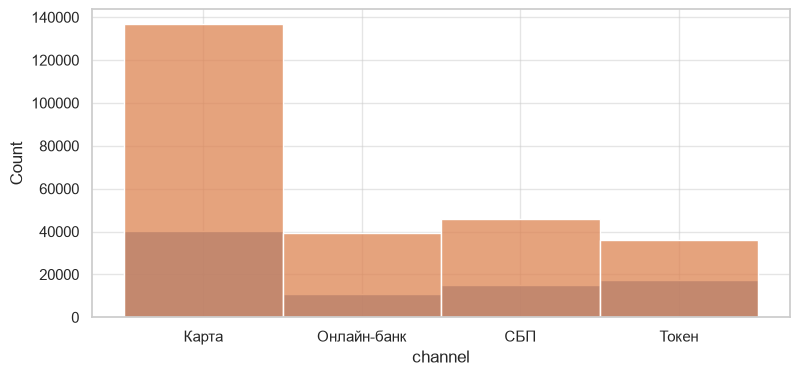

In [62]:
drop_statuses = [
    'Ранний отток в конце 2024',
    'Полный отток (в 2025)',
    'Резкое падение (>50%)',
    'Умеренное падение (15-50%)'
]

clientIdDrop=clientProfile[ clientProfile['dynamics_status'].isin(drop_statuses)]['client_id']

afterDrop=dfTransactions[ (dfTransactions['client_id'].isin(clientIdDrop)) & (dfTransactions['txn_datetime']>='2025-01-01') ]
beforeDrop=dfTransactions[(dfTransactions['client_id'].isin(clientIdDrop)) & (dfTransactions['txn_datetime'] <'2025-01-01')]


plt.figure(figsize=(9, 4))
sns.histplot(data=afterDrop['channel'])
sns.histplot(data=beforeDrop['channel'])
plt.show()


Разбиваем клиентов на 4 группы:
   1. Премиальный сегмент с тратами выше медианной, со снижением активности (297)
   2. Зарплатные клиенты со снижением активности (740)
   3. Массовый c приложением, со снижением активности (585)
   4. Лояльные клиенты с большим оборотом в прошлом, со снижением активности (174)

Всего получается 1796 клиентов. Если клиент подходит под несколько групп, то определяем его в наиболее приоритетную категорию (приоритет соответствует написанному выше, т.е. самые приоритетные – премиальный сегмент с тратами выше медианной, после идут зарплатные клиенты и т.д.)
Для определения причин падения заинтересованности каждой из категорий необходимо выполнить анализ данных по группам.

In [63]:
# Получаем список уникальных групп оттока (исключая 'Исключен')
group_names = [g for g in clientProfile['group'].unique() if g != 'Исключен']

if 'dfTransactions' in globals():
    # Объединяем транзакции с профилем клиентов по группам
    tx_analysis = dfTransactions.merge(clientProfile[['client_id', 'group']], on='client_id', how='inner')
    tx_analysis = tx_analysis[tx_analysis['group'] != 'Исключен'].copy()

    # Считаем точное количество уникальных клиентов в каждой группе
    group_client_counts = clientProfile[clientProfile['group'] != 'Исключен'].groupby('group')['client_id'].nunique()

    # Разделяем на периоды
    tx_analysis['period'] = np.where(tx_analysis['txn_datetime'] <= '2024-12-31', '2024',
                                   np.where(tx_analysis['txn_datetime'] >= '2025-01-01', '2025_H1', 'other'))
    tx_analysis = tx_analysis[tx_analysis['period'] != 'other']

    for grp_name in group_names:

        sub = clientProfile[clientProfile['group'] == grp_name]
        print(f"\n================ ГРУППА: {grp_name} (Клиентов: {len(sub)}) ================")

        print("\n[Гипотеза 1] Источники дохода (income_source, %):")
        print(sub['income_source'].value_counts(normalize=True).mul(100).round(1))

        print("\n[Гипотеза 2] Типы карт (card_type, %):")
        print(sub['card_type'].value_counts(normalize=True).mul(100).round(1))

        print("\n[Гипотеза 3] Наличие мобильного приложения (has_mobile_app, %):")
        print(sub['has_mobile_app'].value_counts(normalize=True).mul(100).round(1))



        sub_tx = tx_analysis[tx_analysis['group'] == grp_name]
        n_people = group_client_counts.get(grp_name, 1)

        # Считаем валовую сумму по категориям для всей группы за периоды
        cat_piv = sub_tx.pivot_table(index='category', columns='period', values='amount', aggfunc='sum', fill_value=0)

        # Применяем вашу логику: (Сумма группы / Кол-во людей) / Кол-во месяцев (12 для 2024, 6 для 2025 H1)
        if '2024' in cat_piv.columns:
            cat_piv['2024_monthly_per_capita'] = (cat_piv['2024'] / n_people) / 12
        if '2025_H1' in cat_piv.columns:
            cat_piv['2025_monthly_per_capita'] = (cat_piv['2025_H1'] / n_people) / 6

        if '2024_monthly_per_capita' in cat_piv.columns and '2025_monthly_per_capita' in cat_piv.columns:
            cat_piv['drop_%'] = ((cat_piv['2025_monthly_per_capita'] - cat_piv['2024_monthly_per_capita']) / cat_piv['2024_monthly_per_capita'] * 100).round(1)
            print(cat_piv[['2024_monthly_per_capita', '2025_monthly_per_capita', 'drop_%']].sort_values(by='2024_monthly_per_capita', ascending=False).head(7))


================ ГРУППА: Массовый c приложением, со снижением активности (Клиентов: 679) ================

[Гипотеза 1] Источники дохода (income_source, %):
income_source
Зарплата в другом банке    54.7
Зарплата в нашем банке     45.3
Name: proportion, dtype: float64

[Гипотеза 2] Типы карт (card_type, %):
card_type
Дебетовая      79.1
Кредитная      20.0
Премиальная     0.9
Name: proportion, dtype: float64

[Гипотеза 3] Наличие мобильного приложения (has_mobile_app, %):
has_mobile_app
True    100.0
Name: proportion, dtype: float64
period               2024_monthly_per_capita  2025_monthly_per_capita  drop_%
category                                                                     
Одежда и обувь                   3564.675053              1499.863831   -57.9
Продукты                         2724.393790              1464.620814   -46.2
Развлечения и досуг              1778.696828               633.485581   -64.4
Азс                              1349.409602               657.450926  

1) В группе клиентов "массовых с приложением" наблюдается спад активности, который можно обосновать зарплатой в другом банке (54.7%), т.е. у половины клиентов из этой категории основное количество денег не хранится в нашем банке. По всем категориям наблюдается спад от 43% до 64%, больше всего просела категория "Развлечения и досуг" (-64.4%).
2) Похожая ситуация у клиентов из категории "Лояльные клиенты с большим оборотом в прошлом". У них также большая часть имеют источник зарплаты сторонний банк (55.8%). Также 61% из этой категории не имеют мобильного приложения, что также отражается на активности. Также по всем категориям наблюдается спад от 40.6% до 65.8%, больше всего упали траты в категории "Развлечение и досуг"
3)  У клиентов из категории "Зарплатные клиенты" уже ситуация другая большая часть имеют источник зарплаты нащ банк (93.4%). Также только 40% из этой категории не имеют мобильного приложения, это отражается на активности. Также по всем категориям наблюдается спад от 37.3% до 62.0%, больше всего упали траты в категории "Развлечение и досуг" (62%) (Я не знаю как объяснить падение активности у этого сегмента клиентов)
4) Клиенты из категории "Премиальный сегмент с тратами выше медианной": зарплата не в нашем банке у 53.2%, а 46.6% не имеют мобильное приложение, эти два фактора сильнее всего влияют на активность пользователей.

### 7.1. Кого в кампанию не берём и почему

1) В кампанию не берём клиентов у которых наблюдается рост активности или стабильное значение активности. Они и так заинтересованы в нашем банке, поэтому их и не трогаем.
2) Также не берём людей, которые не согласны на маркетинговую коммуникацию.
3) Не берём клиентов массовых без приложения с тратами ниже меридианной (среди массовых клиентов). Клиентам с приложением легче вернуть интерес к банку. Лучше выбрать людей с тратами выше меридианной ибо они приносят больший оборот чем другие клиенты из этой же категории.
4) Если клиент не подходит по остальным критериям, смотрим на лояльность, берём людей с низкой лояльностью их будет трудно обратно. Даже если лояльность выше базовой проверяем на какую сумму он совершил транзакций и отбираем только с тратами выше меридианных по этой категории в прошлом.

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

- **Гипотеза «падение связано с типом карты» не подтвердилась.** В массовой группе 79.1% дебетовых карт, в зарплатной — 67.9%, в премиуме — 34.0% дебетовых и 42.5% премиальных. Падение есть во всех типах карт, одного типа-драйвера нет.
- **Гипотеза «виновато только отсутствие приложения» не подтвердилась.** В группе массовых с приложением приложение есть у 100% клиентов, но падение по категориям всё равно составляет 43–64%.
- **Гипотеза «премиум устойчивее» не подтвердилась.** В премиуме «Развлечения» падают на 67.7%, «Одежда» — на 39.5%; это не меньше, чем в массовых группах.
- **Гипотеза «причина — уход зарплаты из банка» не подтвердилась для зарплатной группы.** В зарплатной группе 93.4% получают зарплату в нашем банке, но падение сохраняется: «Развлечения» -62.0%, «Одежда» -49.6%.
- **Гипотеза «падение только у клиентов без приложения» не подтвердилась.** В лояльной группе 61.0% без приложения, но в массовой группе с приложением падение тоже сильное.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [64]:


dfClients.to_parquet("clean_data.parquet", index=False)

cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")

if 'campaign' in globals():
    campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")
elif 'clientProfile' in globals():
    clientProfile[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")
else:
    dfClients[["client_id"]].assign(group="Основная").to_csv("campaign_list.csv", index=False, encoding="utf-8")